In [1]:
import cudf
import cuml
import cupy as cp
import matplotlib.pyplot as plt
import seaborn as sns
from cuml.model_selection import train_test_split
from cuml.preprocessing import StandardScaler, OneHotEncoder, LabelEncoder
from cuml.decomposition import PCA
from cuml.cluster import DBSCAN
from cuml.metrics import confusion_matrix, precision_score, recall_score, f1_score, accuracy_score
from sklearn.model_selection import ParameterGrid
import numpy as np
import warnings
import kagglehub
warnings.filterwarnings('ignore')

In [2]:
cuml.set_global_output_type('cupy')

In [3]:
def draw_confusion_matrix(cm, title='Confusion Matrix'):
    plt.figure(figsize=(6, 4))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=False,
                xticklabels=['Not Fraud', 'Fraud'], yticklabels=['Not Fraud', 'Fraud'])
    plt.title(title)
    plt.xlabel('Predicted')
    plt.ylabel('Actual')
    plt.show()

In [4]:
def print_confusion_matrix(cm, title):
    print(f"{title}:")
    print("         Predicted")
    print("         Not Fraud  Fraud")
    print("Actual")
    print(f"Not Fraud  {cm[0,0]:6d}  {cm[0,1]:6d}")
    print(f"Fraud      {cm[1,0]:6d}  {cm[1,1]:6d}")

In [5]:
path = kagglehub.dataset_download("ealaxi/banksim1")
print("Path to dataset files:", path)

100%|██████████| 13.1M/13.1M [00:01<00:00, 9.14MB/s]

Extracting files...


Path to dataset files: /root/.cache/kagglehub/datasets/ealaxi/banksim1/versions/1


In [6]:
data = cudf.read_csv(path + '/bs140513_032310.csv')

In [7]:
data = data.drop(['zipcodeOri', 'zipMerchant'], axis=1)
data['customer'] = data['customer'].str[1:-1]
data['age'] = data['age'].str[1:-1]
data['gender'] = data['gender'].str[1:-1]
data['merchant'] = data['merchant'].str[1:-1]
data['category'] = data['category'].str.replace('es_', '')
data = data[data['gender'] != 'U']
data['age'] = data['age'].replace('U', '7')
data['age'] = data['age'].astype('float32')

In [8]:
data['amount'] = data['amount'].astype('float32')
data['amount_thresh'] = cudf.Series('>3000', index=data.index)
data.loc[data['amount'] <= 500, 'amount_thresh'] = '0-500'
data.loc[(data['amount'] > 500) & (data['amount'] <= 1000), 'amount_thresh'] = '500-1000'
data.loc[(data['amount'] > 1000) & (data['amount'] <= 1500), 'amount_thresh'] = '1000-1500'
data.loc[(data['amount'] > 1500) & (data['amount'] <= 2000), 'amount_thresh'] = '1500-2000'
data.loc[(data['amount'] > 2000) & (data['amount'] <= 2500), 'amount_thresh'] = '2000-2500'
data.loc[(data['amount'] > 2500) & (data['amount'] <= 3000), 'amount_thresh'] = '2500-3000'

In [9]:
customer = data.groupby('customer').size().reset_index(name='customer_total_trans')
customer['customer_ID'] = cp.arange(1, len(customer) + 1)

merchant = data.groupby('merchant').size().reset_index(name='merchant_total_trans')
merchant['merchant_ID'] = cp.arange(1, len(merchant) + 1)

category = data.groupby('category').size().reset_index(name='category_total_trans')
category['category_ID'] = cp.arange(1, len(category) + 1)

amount_thresh = data.groupby('amount_thresh').size().reset_index(name='amount_thresh_total_trans')
amount_thresh['amount_thresh_ID'] = cp.arange(1, len(amount_thresh) + 1)

In [10]:
data = data.merge(customer, on='customer').merge(merchant, on='merchant')
data = data.drop(['customer', 'merchant'], axis=1)
data = data.merge(category, on='category').merge(amount_thresh, on='amount_thresh')
data['category'] = data['category_ID']
data['amount_thresh'] = data['amount_thresh_ID']
data = data.drop(['category_ID', 'amount_thresh_ID'], axis=1)

age = data.groupby('age').size().reset_index(name='age_total_trans')
gender = data.groupby('gender').size().reset_index(name='gender_total_trans')
data = data.merge(age, on='age').merge(gender, on='gender')

In [11]:
total_freq = len(data)
data['merchant_total_trans'] = (data['merchant_total_trans'] / total_freq * 100).round(5)
data['category_total_trans'] = (data['category_total_trans'] / total_freq * 100).round(5)
data['amount_thresh_total_trans'] = (data['amount_thresh_total_trans'] / total_freq * 100).round(5)
data['age_total_trans'] = (data['age_total_trans'] / total_freq * 100).round(5)
data['gender_total_trans'] = (data['gender_total_trans'] / total_freq * 100).round(5)

data = data.drop('step', axis=1)
data = data[['fraud'] + [col for col in data.columns if col != 'fraud']]

In [12]:
ohe = OneHotEncoder(sparse=True, handle_unknown='ignore')
ohe_cols = ['age', 'gender', 'category', 'amount_thresh']
ohe_data = ohe.fit_transform(data[ohe_cols])
ohe_feature_names = ohe.get_feature_names(ohe_cols)
ohe_data = cudf.DataFrame(ohe_data, columns=ohe_feature_names)
data = cudf.concat([data.drop(ohe_cols, axis=1), ohe_data], axis=1)

In [13]:
le = LabelEncoder()
data['fraud'] = le.fit_transform(data['fraud'])

print("Data dimensions:", data.shape)

Data dimensions: (594128, 43)


In [14]:
pca_cols = ['age_0.0', 'age_1.0', 'age_2.0', 'age_3.0', 'age_4.0', 'age_5.0', 'age_6.0', 'age_7.0',
            'gender_E', 'gender_F', 'gender_M',
            'category_1', 'category_2', 'category_3', 'category_4', 'category_5', 'category_6', 'category_7',
            'category_8', 'category_9', 'category_10', 'category_11', 'category_12', 'category_13', 'category_14',
            'amount', 'amount_thresh_1', 'amount_thresh_2', 'amount_thresh_3', 'amount_thresh_4', 'amount_thresh_5',
            'amount_thresh_6', 'amount_thresh_7']
scaler = StandardScaler()
scaled_data_big = scaler.fit_transform(data[pca_cols])
pca = PCA(n_components=2)
pca_data = pca.fit_transform(scaled_data_big)
pca_df = cudf.DataFrame(pca_data, columns=['PC1', 'PC2'])
pca_df['fraud'] = data['fraud']

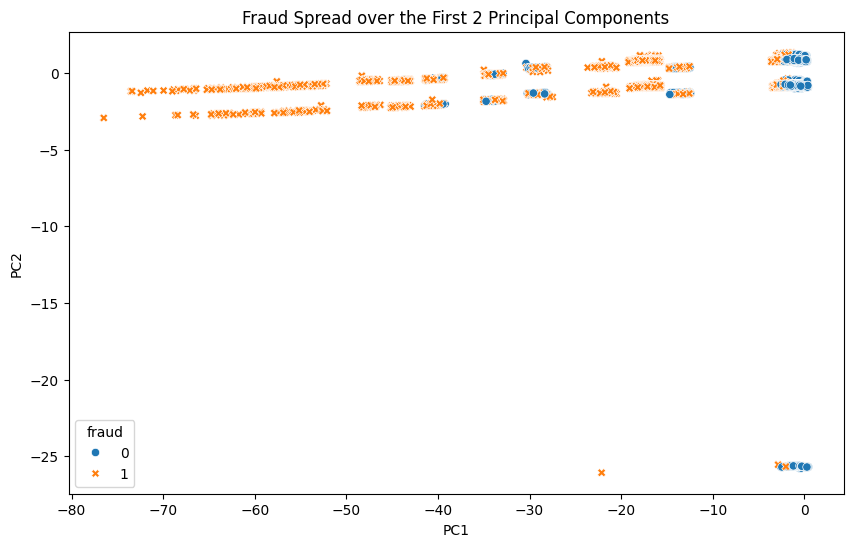

Explained variance ratio: [0.09855864 0.06097488]


In [15]:
pca_df_np = pca_df.to_pandas()
plt.figure(figsize=(10, 6))
sns.scatterplot(x='PC1', y='PC2', hue='fraud', style='fraud', data=pca_df_np)
plt.title('Fraud Spread over the First 2 Principal Components')
plt.xlabel('PC1')
plt.ylabel('PC2')
plt.show()

print("Explained variance ratio:", cp.asnumpy(pca.explained_variance_ratio_))

In [16]:
X = data.drop('fraud', axis=1)
y = data['fraud']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=123, stratify=y)

In [17]:
X_sample = X_train.copy()
y_sample = y_train.copy()

In [18]:
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_sample)

In [19]:
param_grid = {
    'eps': [1.6, 1.65, 1.7, 1.75, 1.8],  # Test near best-performing eps
    'min_samples': [2, 3, 4],             # Test adjacent min_samples
    'fraud_threshold': [0.05, 0.10]       # Test lower thresholds
}

In [20]:
best_f1 = -1
best_recall = -1
best_params = None
best_labels = None
results = []

In [ ]:
for params in ParameterGrid(param_grid):
    dbscan = DBSCAN(eps=params['eps'], min_samples=params['min_samples'])
    labels = dbscan.fit_predict(X_scaled)

    if len(cp.unique(labels)) > 1:
        temp_data = cudf.DataFrame({
            'cluster': labels,
            'true_label': y_sample
        })

        cluster_mapping = {}
        for cluster in cp.unique(labels).get():
            if cluster != -1:
                mask = temp_data['cluster'] == cluster
                fraud_ratio = temp_data[mask]['true_label'].mean()
                cluster_mapping[cluster] = 1 if fraud_ratio > params['fraud_threshold'] else 0

        temp_data['predicted'] = temp_data['cluster'].map(cluster_mapping).fillna(0)

        y_true = y_sample.to_numpy()
        y_pred = temp_data['predicted'].to_numpy()

        cm = confusion_matrix(y_true, y_pred)
        precision = precision_score(y_true, y_pred, zero_division=0)
        recall = recall_score(y_true, y_pred, zero_division=0)
        f1 = f1_score(y_true, y_pred)
        accuracy = accuracy_score(y_true, y_pred)

        results.append({
            'params': params,
            'f1': f1,
            'recall': recall,
            'precision': precision,
            'accuracy': accuracy,
            'confusion_matrix': cm
        })

        print(f"eps={params['eps']:.2f}, min_samples={params['min_samples']}, threshold={params['fraud_threshold']:.0%}")
        print(f"F1={f1:.4f}, Recall={recall:.4f}, Precision={precision:.4f}, Accuracy={accuracy:.4f}")

        if f1 > best_f1 or (f1 == best_f1 and recall > best_recall):
            best_f1 = f1
            best_recall = recall
            best_params = params
            best_labels = labels

print("\n=== Best Model ===")
print(f"Parameters: eps={best_params['eps']}, min_samples={best_params['min_samples']}, fraud_threshold={best_params['fraud_threshold']:.0%}")
print(f"F1: {best_f1:.4f}, Recall: {best_recall:.4f}")


[2025-07-09 07:26:43.183] [CUML] [warning] Batch size limited by the chosen integer type (4 bytes). 5614 -> 4819. Using the larger integer type might result in better performance
